# PEP activity–density map: 11 × 11

**Finite-time clustering map, not a stationary phase diagram.**

This extends the earlier PEP demonstration with the same update rule and observables. It does not extend the attractive lattice-gas dynamics: there is no attraction energy, temperature, or Metropolis acceptance.

Question: at a fixed observation time, is stronger persistence associated with larger density inhomogeneity across densities?

## Fixed design

| Quantity | Frozen value |
|---|---|
| Lattice | 20 × 20, periodic, fixed N |
| Persistence A = 1/alpha | 11 logarithmically spaced points from 1 to 20 |
| Density rho | 11 equally spaced points from 0.1 to 0.9 |
| Replicates | Seeds 2026111141 and 2026111142 at every point |
| Duration | 500 sweeps; N attempts per sweep |
| Measurements | Every 10 sweeps, including the initial state |
| Summary window | Sweeps 410, 420, …, 500: ten correlated measurements |
| Main colours | S_low and local-density variance (5 × 5 windows) |
| Total | 121 parameter combinations, 242 trajectories, 24,200,000 attempts |

A sweep contains N attempts, so equal sweep counts across densities do not imply equal computational work.

Within each density and seed, initial states and random-event streams are paired across A. Separate density-index streams are used across densities. Two seeds are insufficient for reliable confidence intervals. A is a persistence control, not calibrated ABP Pe or expTM prior variance.

Technical success requires all implementation checks, conserved finite trajectories, complete records, and agreement between saved snapshots and measured heatmap observables. Failure stops the run. Stop after the fixed grid; do not tune seeds, extend trajectories, or fit a phase boundary to these results.

For a prespecified descriptive comparison, report A=20 minus A=1 separately for both seeds at each density. Positive values in both seeds mean descriptive agreement only, not statistical significance or steady-state validation.

## Open and run

Extract the **complete ZIP**, open its folder in VS Code, and select a kernel with NumPy and Matplotlib. Run cells in order. The default reads the completed host run. Set RUN_GRID=True only to repeat the entire fixed experiment on your computer. This notebook requires pep_core.py and map11.py beside it.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "map11.py").is_file():
    PROJECT_DIR = Path(r"C:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas-active")
# If needed, replace PROJECT_DIR with the extracted folder's absolute path.
assert (PROJECT_DIR / "map11.py").is_file(), "Open the extracted package folder or set PROJECT_DIR."
sys.path.insert(0, str(PROJECT_DIR))
from map11 import CONFIG, PROTOCOL_SHA, run_map, verify_saved
print("Protocol:", PROTOCOL_SHA)
print("Densities:", CONFIG["densities"])
print("Persistence A:", CONFIG["persistence_A"])
print("Tumble probabilities alpha:", 1/np.array(CONFIG["persistence_A"]))


Python: 3.14.2 NumPy: 2.4.1
Working directory: c:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas-active
{
  "periodic_move_and_tumble_before_hop": true,
  "exclusion_and_blocked_tumbling": true,
  "ballistic_and_empty_limits": true,
  "independent_reference_2000_events": true,
  "exact_SEP_36_states_and_structure_reference": true,
  "analytic_orientation_kernel": true,
  "periodic_structure_known_answers": true,
  "state_and_rng_replay": true,
  "status": "IMPLEMENTATION_CHECKS_PASSED"
}
Protocol: 722498bacc278c07f4e9df04baa59fc0f13a30e680075ba079a9c2116a028621
Densities: [0.1, 0.18, 0.26, 0.33999999999999997, 0.42000000000000004, 0.5, 0.58, 0.66, 0.74, 0.82, 0.9]
Persistence A: [1.0, 1.3492828476735632, 1.8205642030260802, 2.4564560522315806, 3.314454017339987, 4.47213595499958, 6.034176336545162, 8.141810630738087, 10.985605433061178, 14.822688982138951, 20.0]
Tumble probabilities alpha: [1.         0.74113445 0.54928027 0.40709053 0.30170882 0.2236068
 0.1657227

## 1 — Execute the fixed grid or read the completed example

RUN_GRID=False reads completed_run/ and does not generate trajectories. RUN_GRID=True creates a new runs_map11/map11_<time>_<id>/ directory, leaving previous runs intact. Progress is printed after each density. Checkpoints are retained every 100 sweeps, but automatic resumption is not implemented; an interrupted run is not complete evidence.


In [2]:
RUN_GRID = False
if RUN_GRID:
    RUN = run_map(PROJECT_DIR / "runs_map11")
else:
    RUN = PROJECT_DIR / "completed_run"
assert RUN.is_dir(), "The completed_run folder is missing; extract the full ZIP or execute RUN_GRID=True."
print("Results:", RUN)
print(json.loads((RUN / "status.json").read_text()))


Results: c:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas-active\completed_run
{'status': 'completed', 'completed_trajectories': 242, 'attempts': 24200000, 'seconds': 436.8313762449998, 'stationarity_validated': False, 'training_data_qualified': False}


## 2 — Unified plots: density on x, persistence on y

Every panel uses **density rho on x** and **persistence A=1/alpha on y (log scale)**.
The colours show the named clustering observable, not mean density. A is the PEP persistence control, not expTM prior variance or ABP Pe.

Mean and individual-seed panels share the same 0-to-maximum scale for each observable, using viridis. Absolute seed differences use viridis with their own labelled limits. Signed changes relative to A=1 use a symmetric red–white–blue scale centred at zero. Different observables do not share numerical limits.

This cell reads saved summaries and saves figures under RUN/figures_density_x/. It does not sample, train, or alter simulation records. The old duplicate previews have been removed.


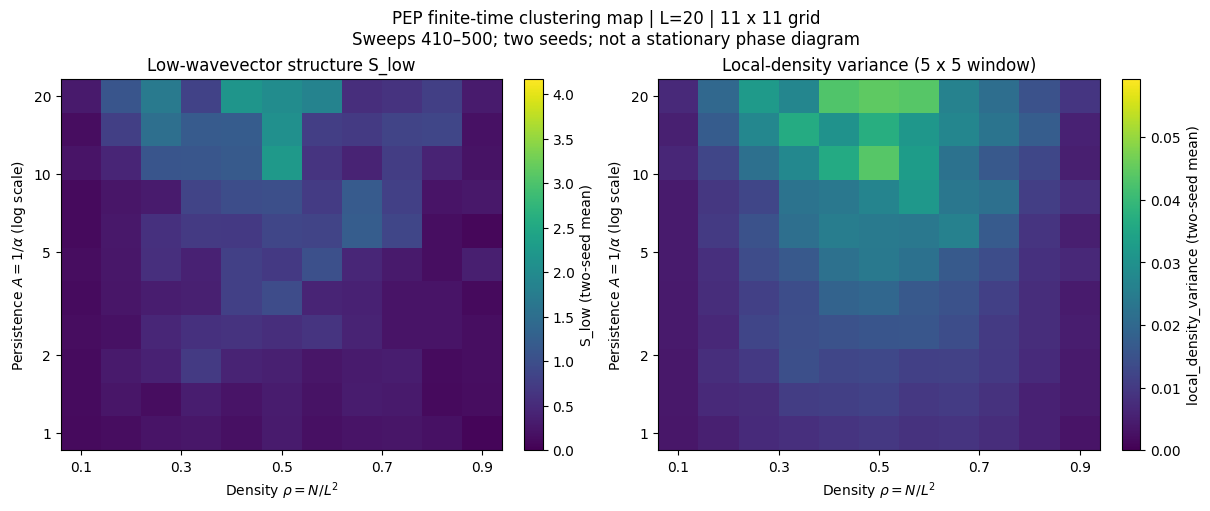

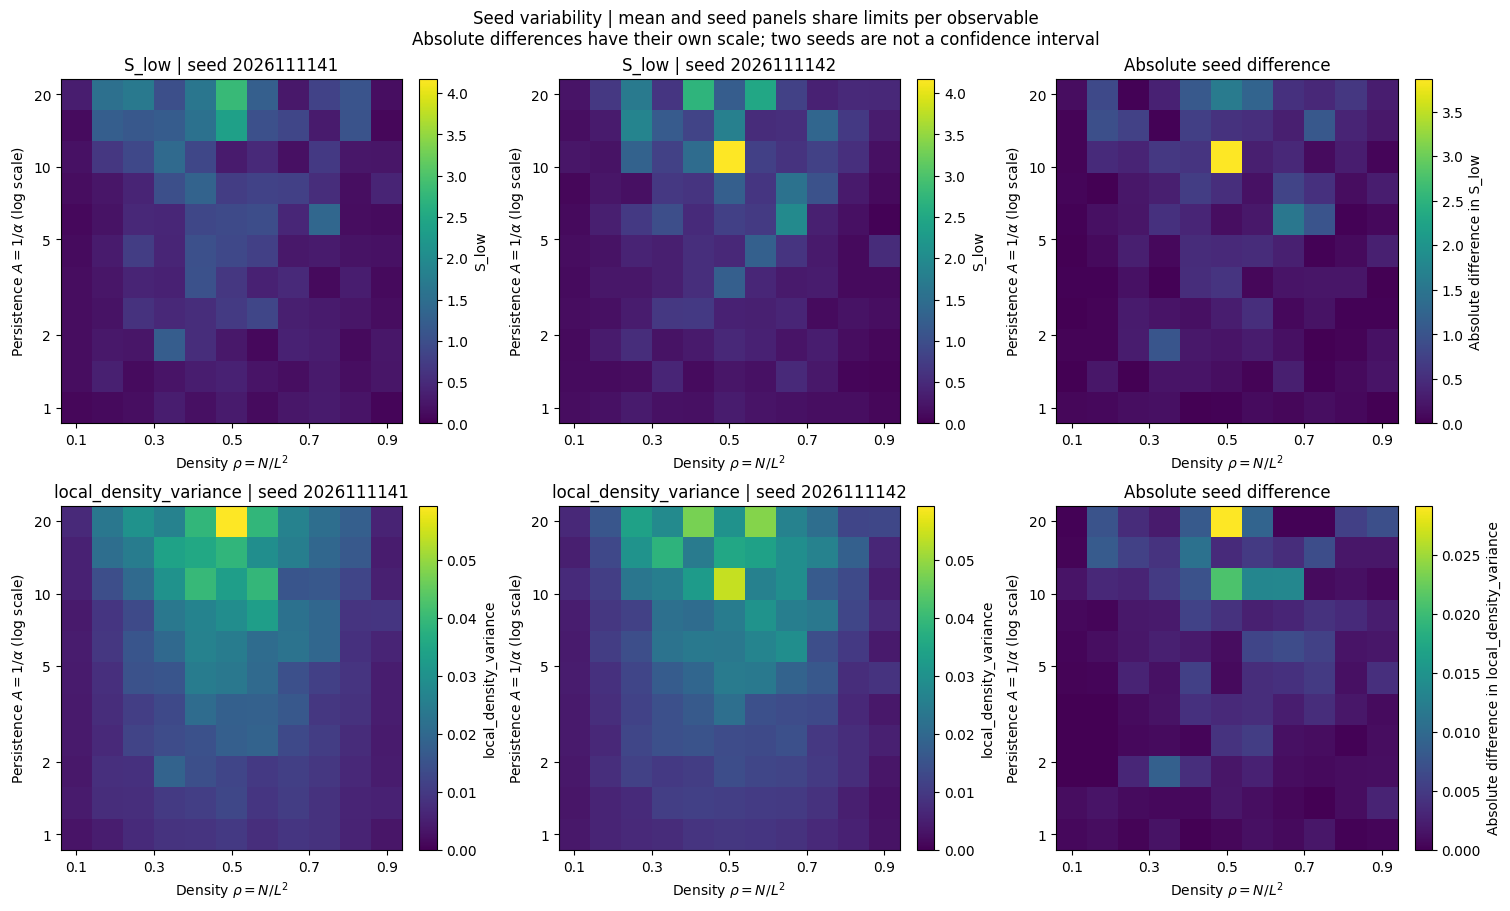

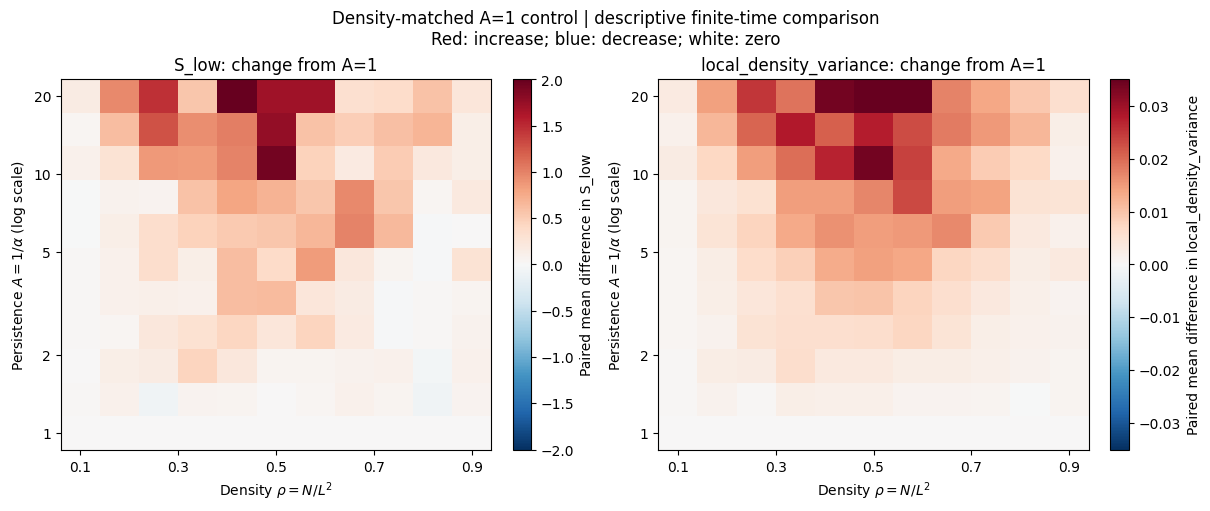

Figures saved to: c:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas-active\completed_run\figures_density_x
Source run: c:\Users\user\Documents\GitHub\active-matter-reproductions\lattice-gas-active\completed_run


In [3]:
from map11 import load_arrays

# Plot existing records only. Keep frozen simulator source unchanged.
config, arrays = load_arrays(RUN)
rho = np.asarray(config['densities'])
A = np.asarray(config['persistence_A'])
FIGURES = RUN / 'figures_density_x'
FIGURES.mkdir(exist_ok=True)
labels = {'S_low': 'Low-wavevector structure S_low',
          'local_density_variance': 'Local-density variance (5 x 5 window)'}
# A common scale for the mean and both seeds, separately for each observable.
limits = {key: max(float(arrays[key].max()), 1e-12) for key in labels}

def draw_unified(ax, values, title, vmin, vmax, cmap='viridis'):
    assert values.shape == (len(rho), len(A))
    # Geometric edges preserve equal logarithmic spacing along persistence.
    xe = np.r_[rho[0] - (rho[1]-rho[0])/2,
               (rho[:-1]+rho[1:])/2, rho[-1]+(rho[-1]-rho[-2])/2]
    middle = np.sqrt(A[:-1]*A[1:])
    ye = np.r_[A[0]**2/middle[0], middle, A[-1]**2/middle[-1]]
    im = ax.pcolormesh(xe, ye, values.T, shading='flat',
                       cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_yscale('log')
    ax.set(xlabel=r'Density $\rho=N/L^2$',
           ylabel=r'Persistence $A=1/\alpha$ (log scale)', title=title)
    ax.set_xticks([.1, .3, .5, .7, .9])
    ax.set_yticks([1, 2, 5, 10, 20], ['1', '2', '5', '10', '20'])
    ax.minorticks_off()
    return im

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, key in zip(axes, labels):
    im = draw_unified(ax, arrays[key].mean(axis=0), labels[key], 0, limits[key])
    fig.colorbar(im, ax=ax, label=key + ' (two-seed mean)')
fig.suptitle('PEP finite-time clustering map | L=20 | 11 x 11 grid\n'
             'Sweeps 410–500; two seeds; not a stationary phase diagram')
fig.savefig(FIGURES / 'clustering_map.png', dpi=180)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(15, 9), layout='constrained')
for row, key in enumerate(labels):
    values = arrays[key]
    for si in range(2):
        im = draw_unified(axes[row, si], values[si],
                          f'{key} | seed {config["seeds"][si]}', 0, limits[key])
        fig.colorbar(im, ax=axes[row, si], label=key)
    difference = np.abs(values[0]-values[1])
    im = draw_unified(axes[row, 2], difference, 'Absolute seed difference',
                      0, max(float(difference.max()), 1e-12))
    fig.colorbar(im, ax=axes[row, 2], label='Absolute difference in ' + key)
fig.suptitle('Seed variability | mean and seed panels share limits per observable\n'
             'Absolute differences have their own scale; two seeds are not a confidence interval')
fig.savefig(FIGURES / 'seed_comparison.png', dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, key in zip(axes, labels):
    delta = (arrays[key]-arrays[key][:, :, 0, None]).mean(axis=0)
    bound = max(float(np.abs(delta).max()), 1e-12)
    im = draw_unified(ax, delta, key + ': change from A=1', -bound, bound, 'RdBu_r')
    fig.colorbar(im, ax=ax, label='Paired mean difference in ' + key)
fig.suptitle('Density-matched A=1 control | descriptive finite-time comparison\n'
             'Red: increase; blue: decrease; white: zero')
fig.savefig(FIGURES / 'matched_density_contrast.png', dpi=180)
plt.show()

# Calculate the original endpoint comparison without modifying source records.
comparison = []
for di, density in enumerate(rho):
    record = {'density': float(density)}
    for key in labels:
        delta = arrays[key][:, di, -1]-arrays[key][:, di, 0]
        record[key] = {'A20_minus_A1_by_seed': delta.tolist(),
                       'positive_in_both_seeds': bool(np.all(delta > 0))}
    comparison.append(record)
print('Figures saved to:', FIGURES)
print('Source run:', RUN)


## 3 — Inspect the prespecified endpoint comparison

For each density, the table reports A=20 minus A=1 in the same finite-time window. Keep negative and mixed results. A lack of agreement across seeds is not repaired by choosing different seeds or extending selected points.


In [4]:
for row in comparison:
    print(f"rho={row['density']:.2f}")
    for key in ("S_low", "local_density_variance"):
        print(" ", key, row[key])


rho=0.10
  S_low {'A20_minus_A1_by_seed': [0.26310393785654096, 0.07693244481984349], 'positive_in_both_seeds': True}
  local_density_variance {'A20_minus_A1_by_seed': [0.0036408000000000005, 0.002845600000000001], 'positive_in_both_seeds': True}
rho=0.18
  S_low {'A20_minus_A1_by_seed': [1.4242317135809452, 0.487821659961174], 'positive_in_both_seeds': True}
  local_density_variance {'A20_minus_A1_by_seed': [0.0186144, 0.0101528], 'positive_in_both_seeds': True}
rho=0.26
  S_low {'A20_minus_A1_by_seed': [1.5324747112433177, 1.4129221340789704], 'positive_in_both_seeds': True}
  local_density_variance {'A20_minus_A1_by_seed': [0.023208, 0.027062399999999997], 'positive_in_both_seeds': True}
rho=0.34
  S_low {'A20_minus_A1_by_seed': [0.6635031862840649, 0.4647748441170999], 'positive_in_both_seeds': True}
  local_density_variance {'A20_minus_A1_by_seed': [0.0174248, 0.0208976], 'positive_in_both_seeds': True}
rho=0.42
  S_low {'A20_minus_A1_by_seed': [1.4761921149554045, 2.5356929621457

## 4 — Optional saved-data verification

This checks all 12,342 saved measurement frames: fixed particle number, occupation/orientation consistency, both heatmap observables recomputed from occupation snapshots, and window means. This is a reproducibility check, not another simulation or a stationarity test. The completed host run has already passed it.


In [5]:
VERIFY_SAVED = False
if VERIFY_SAVED:
    print("Verified frames:", verify_saved(RUN))
else:
    validation = RUN / "validation.json"
    print(json.loads(validation.read_text()) if validation.exists() else "Not yet checked for this RUN. Set VERIFY_SAVED=True.")


{'status': 'SAVED_DATA_CHECKS_PASSED', 'trajectories': 242, 'frames_recomputed': 12342, 'checks': 'Conservation, occupation/orientation agreement, both heatmap observables recomputed, fixed-window means verified.'}


## Scientific interpretation and stopping decision

This map describes a fixed finite-time observable under random initial conditions. Both seed variation and temporal correlations matter. No stationary sampling, MIPS boundary, qualified training set, or physical expTM mapping has been established. The earlier equilibrium NOT READY and Track B STOP decisions remain unchanged.

Retain all raw records and stop after this bounded map. A further investigation requires a separate scientific question and decision; a visually appealing heatmap is not, by itself, justification for a larger scan.

Reference for the PEP rule: Soto & Golestanian, Phys. Rev. E 89, 012706 (2014), Section II; https://doi.org/10.1103/PhysRevE.89.012706.
